# Using CO2 PPM to Predict Extreme Weather Pattens

**Team members:** [Sherlock Chen, Edward Christopher, Henry Fong]  
**Repository:** [https://github.com/cjulianan/DS_3001_Semester_Project]

## Setup

Use relative paths and keep the notebook runnable from beginning to end.

In [25]:
from pathlib import Path

DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."

## Import library

In [26]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

## Load data

In [27]:
# Load data from DATA_DIR.

CO2_data = pd.read_excel("data/CO2 PPM over Time.xlsx") # Loads CO2 data
Weather_data = pd.read_excel("data/public_emdat_custom_request.xlsx") # Loads weather data
CH4_data = pd.read_csv("data/ch4_mm_gl.csv", comment = '#') # Loads CH4 data
Nina4_data = pd.read_csv("data/nina4.anom.csv") # Loads nina4 data
Global_temp_data = pd.read_csv("data/global_temp_anomaly.csv") # Loads Global temp anomaly data
DMI_data = pd.read_csv("data/dmi.had.long.csv") # Loads dmi data

## Prepare data

Sources Used:

https://www.geeksforgeeks.org/python/get-the-data-type-of-column-in-pandas-python/

https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-describe-method/

https://www.geeksforgeeks.org/pandas/how-to-rename-columns-in-pandas-dataframe/

https://www.geeksforgeeks.org/python/filter-pandas-dataframe-by-time/

https://www.geeksforgeeks.org/python/pandas-drop-column/

https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-drop_duplicates/

https://www.geeksforgeeks.org/python/python-pandas-dataframe-dropna/

## CO2 PPM Data

In [28]:
# Overview of CO2 Data
CO2_datatype = CO2_data.dtypes
display(CO2_datatype)
display(CO2_data.head(5))
display(CO2_data.describe())

,0
year,int64
month,int64
decimal date,float64
monthly average,float64
de-season alized,float64
#days,int64
st.dev of days,float64
unc. of mon mean,float64


,year,month,decimal date,monthly average,de-season alized,#days,st.dev of days,unc. of mon mean
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99


,year,month,decimal date,monthly average,de-season alized,#days,st.dev of days,unc. of mon mean
count,823.000000,823.000000,823.000000,823.000000,823.000000,823.000000,823.000000,823.000000
mean,1991.958688,6.495747,1992.457736,361.439101,361.431786,19.165249,-1.991592,-0.084593
std,19.812337,3.444685,19.811122,33.511832,33.451725,11.810524,4.478122,0.508127
min,1958.000000,1.000000,1958.202700,312.420000,314.440000,-1.000000,-9.990000,-0.990000
25%,1975.000000,4.000000,1975.333350,331.285000,330.915000,14.500000,0.210000,0.080000
50%,1992.000000,6.000000,1992.458300,356.380000,356.500000,25.000000,0.400000,0.150000
75%,2009.000000,9.000000,2009.583350,387.845000,387.825000,28.000000,0.570000,0.220000
max,2026.000000,12.000000,2026.708300,432.340000,429.550000,31.000000,1.310000,0.580000


In [29]:
# Cleaning CO2 PPM of any data that can cause issues
CO2_data.drop_duplicates(inplace=True)
CO2_data.dropna(inplace=True)

In [30]:
# Removing unnecessary data
CO2_data_dropped = CO2_data.drop(['decimal date', 'monthly average', '#days', 'st.dev of days', 'unc. of mon mean'], axis = 1)
Date1 = CO2_data['year'] >= 2000
Date2 = CO2_data['year'] <= 2025
CO2_data_cleaned = CO2_data_dropped.loc[Date1 & Date2]
CO2_data_cleaned.columns = ['Year', 'Month', 'De-seasonalized'] # Renamed column to start with a uppercase letter for data consistency
display(CO2_data_cleaned.head(5))

,Year,Month,De-seasonalized
502,2000,1,369.24
503,2000,2,368.99
504,2000,3,369.24
505,2000,4,369.44
506,2000,5,368.87


In [31]:
# Clean data and create features.

"""
CO2 - Remove decimal date, de-season alized, #days, st.dev of days, unc. of mon mean
Weather - Keep Disaster Type, Region, and Start Year
"""

CO2_data_cleaned = CO2_data[(CO2_data['year'] >= 2000) & (CO2_data['year'] <= 2025)]
CO2_data_cleaned = CO2_data_cleaned.drop(['decimal date', 'de-season alized', '#days', 'st.dev of days', 'unc. of mon mean'], axis=1)
Weather_data_cleaned = Weather_data[['Disaster Type', 'Region', 'Start Year']]
print(CO2_data_cleaned)
print(Weather_data_cleaned)

     year  month  monthly average
502  2000      1           369.45
503  2000      2           369.71
504  2000      3           370.75
505  2000      4           371.98
506  2000      5           371.75
..    ...    ...              ...
809  2025      8           425.48
810  2025      9           424.37
811  2025     10           424.87
812  2025     11           426.46
813  2025     12           427.49

[312 rows x 3 columns]
     Disaster Type    Region  Start Year
0          Drought    Africa        2025
1            Flood    Africa        2025
2            Flood  Americas        2025
3            Flood      Asia        2024
4         Wildfire  Americas        2025
...            ...       ...         ...
8479         Flood    Africa        2019
8480      Wildfire   Oceania        2019
8481         Storm      Asia        2019
8482         Storm    Europe        2019
8483         Flood    Europe        2019

[8484 rows x 3 columns]


In [32]:
# Check if there are any missing values in either dataset
CO2_missing_values = CO2_data_cleaned.isnull().sum()
Weather_missing_values = Weather_data_cleaned.isnull().sum()

print("CO2 Missing Values:\n", CO2_missing_values)
print("\nWeather Missing Values:\n", Weather_missing_values)

CO2 Missing Values:
 year               0
month              0
monthly average    0
dtype: int64

Weather Missing Values:
 Disaster Type    0
Region           0
Start Year       0
dtype: int64


## Explore data

In [33]:
# Check the counts of how often disasters and regions appear for each
disaster_counts = Weather_data_cleaned["Disaster Type"].value_counts()
region_counts = Weather_data_cleaned["Region"].value_counts()

print("Disaster Type Counts:\n", disaster_counts)
print("\nDisaster Counts by Region:\n", region_counts)

# Also do cross tabulation to find frequency of disaster types for each region
weather_cross_tabulation = pd.crosstab(Weather_data_cleaned["Region"], Weather_data_cleaned["Disaster Type"])
print("\nCross tabulation:\n", weather_cross_tabulation)


Disaster Type Counts:
 Disaster Type
Flood                          4247
Storm                          2855
Extreme temperature             606
Drought                         424
Wildfire                        344
Glacial lake outburst flood       8
Name: count, dtype: int64

Disaster Counts by Region:
 Region
Asia        3198
Americas    2148
Africa      1491
Europe      1342
Oceania      305
Name: count, dtype: int64

Cross tabulation:
 Disaster Type  Drought  Extreme temperature  Flood  \
Region                                               
Africa             179                   17   1015   
Americas           103                   70    913   
Asia                97                  159   1724   
Europe              27                  356    492   
Oceania             18                    4    103   

Disaster Type  Glacial lake outburst flood  Storm  Wildfire  
Region                                                       
Africa                                   0    252  

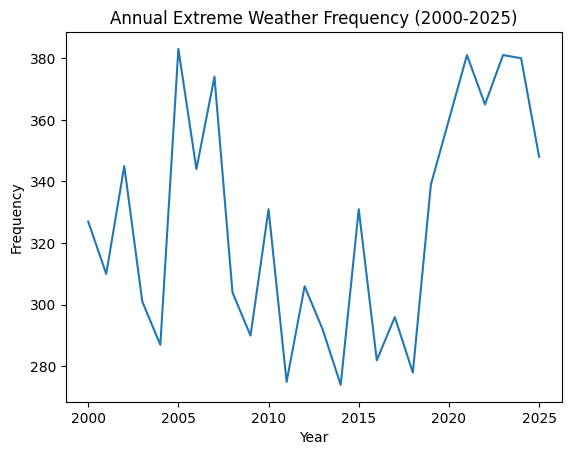

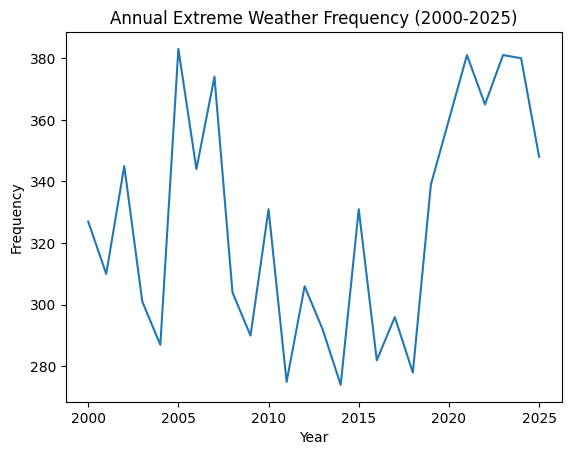

In [34]:
import matplotlib.pyplot as plt

# Group disasters by year
annual_disasters = Weather_data_cleaned["Start Year"].value_counts().sort_index()

# Plot
plt.plot(annual_disasters.index, annual_disasters.values)
plt.title("Annual Extreme Weather Frequency (2000-2025)")
plt.xlabel("Year")
plt.ylabel('Frequency')
plt.show()

## Build models

In [35]:
# Train baseline and candidate models.

## Evaluate models

In [36]:
# Compare models using the chosen evaluation measures.

## Final results

In [37]:
# Generate the final tables and figures.

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]